# sinoLLM — build a tiny language model you can understand

**Start here:** select **Python (mini-LLM PyTorch)** as your Jupyter/VS Code kernel (its interpreter is `.venv-llm/bin/python`), then run cells from top to bottom. Alternatively use a Python environment with `torch`, `matplotlib`, and `ipykernel` installed. No downloads or paid APIs are used by this notebook.

We will train a **character-level, decoder-only transformer from random weights**. It uses the same basic next-token learning idea as larger language models, at a tiny scale. The name is sinoLLM; technically this is a *small educational language model*, not a large or instruction-tuned assistant. Early output may look strange: inspect it rather than assuming it understands language.

**By the end you can:** turn text into IDs, build masked attention, train on next-character targets, inspect loss and attention, generate text, and save/reload the model.

Your earlier notebook learned two numbers for `y = weight × x + bias`. Here we learn thousands of numbers to predict a probability for each possible next character.

In [1]:
import math
import os
import string
import time
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from IPython.display import SVG, display

torch.manual_seed(42)
# Small CPU jobs often run faster with a few threads than with every core.
torch.set_num_threads(min(2, os.cpu_count() or 1))
DEVICE = "cuda" if torch.cuda.is_available() else (
    "mps" if torch.backends.mps.is_available() else "cpu"
)
print(f"PyTorch {torch.__version__} | device: {DEVICE}")

PyTorch 2.14.1 | device: mps


## 1. The whole journey
Read left to right. During **training**, we know the correct next character. During **generation**, we sample a character and feed it back as input.

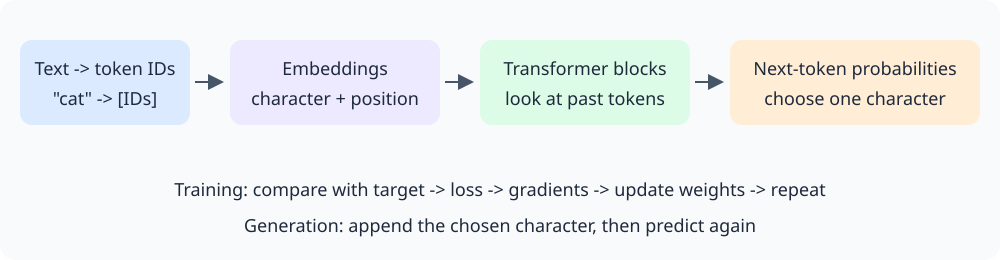

In [2]:
display(SVG("""<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 1000 260" width="100%">
<defs><marker id="a" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8" fill="#475569"/></marker></defs>
<rect width="1000" height="260" rx="16" fill="#f8fafc"/>
<g font-family="sans-serif" font-size="18" fill="#1e293b" text-anchor="middle">
<rect x="20" y="40" width="170" height="85" rx="12" fill="#dbeafe"/><text x="105" y="75">Text -> token IDs</text><text x="105" y="105">"cat" -> [IDs]</text>
<rect x="230" y="40" width="210" height="85" rx="12" fill="#ede9fe"/><text x="335" y="75">Embeddings</text><text x="335" y="105">character + position</text>
<rect x="480" y="40" width="210" height="85" rx="12" fill="#dcfce7"/><text x="585" y="75">Transformer blocks</text><text x="585" y="105">look at past tokens</text>
<rect x="730" y="40" width="250" height="85" rx="12" fill="#ffedd5"/><text x="855" y="75">Next-token probabilities</text><text x="855" y="105">choose one character</text>
<text x="500" y="196">Training: compare with target -> loss -> gradients -> update weights -> repeat</text>
<text x="500" y="232">Generation: append the chosen character, then predict again</text></g>
<g stroke="#475569" stroke-width="2" marker-end="url(#a)"><path d="M195,82 H222"/><path d="M445,82 H472"/><path d="M695,82 H722"/></g></svg>"""))

## 2. Give it text to learn from
The default corpus below is **authored synthetic practice text**. It deliberately repeats simple sentence structures, so a small model can find patterns quickly. A lower validation loss here is evidence of learning these patterns, not broad language ability.

You can later set `DATA_PATH = Path("input.txt")` to use your existing local text. Only use text you are allowed to train on. This notebook never downloads a dataset. For the built-in corpus, we shuffle unique sentences with a fixed seed and hold out whole sentences (new subject/action combinations). File input keeps its original line order. We split before sampling batches, so no batch crosses from training into validation.

In [3]:
DATA_PATH = None  # Optional: Path("input.txt")

subjects = ["the cat", "the dog", "the bird", "the child", "the teacher",
            "the student", "my friend", "the artist", "the farmer", "the baker"]
actions = ["likes the warm sun", "walks near the river", "rests under a tree",
           "looks at the blue sky", "hears a quiet sound", "finds a small flower",
           "watches the rain", "waits beside the door"]
# Fixed ordering keeps this example repeatable without repeating the whole corpus.
practice_lines = [f"{subject} {action}.\n" for action in actions for subject in subjects]
if DATA_PATH is None:
    # Shuffle unique sentences, then hold out whole sentences.
    order = torch.randperm(len(practice_lines), generator=torch.Generator().manual_seed(123))
    lines = [practice_lines[i] for i in order.tolist()]
    corpus_name = "built-in synthetic sentences"
else:
    lines = DATA_PATH.read_text(encoding="utf-8").splitlines(keepends=True)
    if len(lines) < 2:
        raise ValueError("Use a text file with at least two lines.")
    corpus_name = str(DATA_PATH)

cut = int(0.85 * len(lines))
train_text, val_text = "".join(lines[:cut]), "".join(lines[cut:])
print(f"Corpus: {corpus_name}")
print(f"Training: {len(train_text):,} characters | validation: {len(val_text):,}")
print("Example:", repr(train_text[:100]))

Corpus: built-in synthetic sentences
Training: 2,120 characters | validation: 378
Example: 'the bird watches the rain.\nthe baker waits beside the door.\nthe teacher waits beside the door.\nthe b'


## 3. Tokenization: give every character an ID
A token is one unit the model predicts. Here **one character = one token**, including spaces and newlines. Larger language models often use subword tokens instead.

Our vocabulary is fixed in advance: printable ASCII plus newline and tab. The ID is only a label; ID 20 is not 'twice the meaning' of ID 10. Embeddings supply trainable vectors later. Unsupported characters give a clear error rather than silently changing the text.

In [4]:
chars = list("\n\t" + string.ascii_letters + string.digits + string.punctuation + " ")
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}
vocab_size = len(chars)

def encode(text):
    unknown = sorted(set(text) - set(stoi))
    if unknown:
        raise ValueError(f"Unsupported characters: {unknown[:10]!r}. Use ASCII text or extend chars.")
    return [stoi[ch] for ch in text]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

train_ids = torch.tensor(encode(train_text), dtype=torch.long)
val_ids = torch.tensor(encode(val_text), dtype=torch.long)
example = "the cat"
print("Text:   ", repr(example))
print("IDs:    ", encode(example))
print("Decoded:", repr(decode(encode(example))))
assert decode(encode(example)) == example

Text:    'the cat'
IDs:     [21, 9, 6, 96, 4, 2, 21]
Decoded: 'the cat'


## 4. Turn a sentence into many training questions
For `the cat`, inputs are `the ca` and targets are `he cat`: the targets are **one position ahead**.

| Visible prefix | Correct next character |
|---|---|
| `t` | `h` |
| `th` | `e` |
| `the` | space |
| `the ` | `c` |

We compute all these predictions together, but a causal mask prevents each position from reading its future. A **batch** contains several separate text chunks; **context length** is how many characters each chunk can contain.

In [5]:
config = dict(vocab_size=vocab_size, context_length=48, embedding_dim=48,
              num_heads=3, num_layers=2, dropout=0.1)
BATCH_SIZE = 16
TRAIN_STEPS = 300  # First run: keep this small. Increase later to explore.
LEARNING_RATE = 0.003
context_length = config["context_length"]
if min(len(train_ids), len(val_ids)) <= context_length:
    raise ValueError("Both text splits must be longer than the context length.")

batch_rng = torch.Generator().manual_seed(42)
def get_batch(split, generator=batch_rng):
    if split not in ("train", "val"):
        raise ValueError("split must be 'train' or 'val'")
    data = train_ids if split == "train" else val_ids
    starts = torch.randint(len(data) - context_length, (BATCH_SIZE,), generator=generator)
    x = torch.stack([data[i:i + context_length] for i in starts])
    y = torch.stack([data[i + 1:i + context_length + 1] for i in starts])
    return x.to(DEVICE), y.to(DEVICE)

xb, yb = get_batch("train")
print("Input shape:", tuple(xb.shape), "= (batch, time)")
print("Input: ", repr(decode(xb[0].tolist())))
print("Target:", repr(decode(yb[0].tolist())))
assert torch.equal(xb[:, 1:], yb[:, :-1])

Input shape: (16, 48) = (batch, time)
Input:  'friend walks near the river.\nthe cat walks near '
Target: 'riend walks near the river.\nthe cat walks near t'


## 5. Attention: let each position read the past
Each token creates three vectors: **query** (what it looks for), **key** (how others can match it), and **value** (information it contributes). We compare queries with keys, mask the future, then mix values using the resulting weights.

The picture shows **which positions are allowed**, not learned attention weights. Every row is one prediction position. Blue means visible, white means future. The diagonal is allowed: a position knows its own input character while predicting the following character.

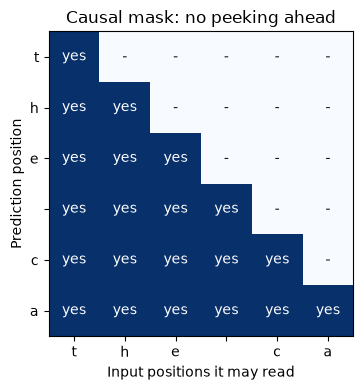

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
mask_demo = torch.tril(torch.ones(6, 6))
ax.imshow(mask_demo.numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(6), list("the ca")); ax.set_yticks(range(6), list("the ca"))
ax.set_xlabel("Input positions it may read"); ax.set_ylabel("Prediction position")
ax.set_title("Causal mask: no peeking ahead")
for row in range(6):
    for col in range(6):
        ax.text(col, row, "yes" if col <= row else "-", ha="center", va="center",
                color="white" if col <= row else "black")
plt.tight_layout(); plt.show()

In [7]:
class CausalSelfAttention(nn.Module):
    def __init__(self, embedding_dim, num_heads, context_length, dropout):
        super().__init__()
        if embedding_dim % num_heads:
            raise ValueError("embedding_dim must be divisible by num_heads")
        self.num_heads = num_heads
        self.head_dim = embedding_dim // num_heads
        self.qkv = nn.Linear(embedding_dim, 3 * embedding_dim)
        self.projection = nn.Linear(embedding_dim, embedding_dim)
        self.attention_dropout = nn.Dropout(dropout)
        self.output_dropout = nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(
            torch.ones(context_length, context_length, dtype=torch.bool)))

    def forward(self, x, return_weights=False):
        batch, time, width = x.shape
        # Separate Q/K/V, then give each head its own slice of the vector.
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        def heads(tensor):
            return tensor.reshape(batch, time, self.num_heads, self.head_dim).transpose(1, 2)
        q, k, v = heads(q), heads(k), heads(v)
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        scores = scores.masked_fill(~self.causal_mask[:time, :time], float("-inf"))
        weights = F.softmax(scores, dim=-1)
        mixed = self.attention_dropout(weights) @ v
        mixed = mixed.transpose(1, 2).contiguous().reshape(batch, time, width)
        output = self.output_dropout(self.projection(mixed))
        return (output, weights) if return_weights else output

## 6. A transformer block: share information, then transform it
**Attention** mixes information across visible positions. The **feed-forward network** transforms each position's vector. **Residual connections** add the original input back; **LayerNorm** normalizes each position's features.

We stack two blocks. An embedding is a vector of trainable numbers, not a guarantee of human-like understanding. The position embedding tells the model where a character occurs in its current window.

In [8]:
class TransformerBlock(nn.Module):
    def __init__(self, embedding_dim, num_heads, context_length, dropout):
        super().__init__()
        self.norm1 = nn.LayerNorm(embedding_dim)
        self.attention = CausalSelfAttention(embedding_dim, num_heads, context_length, dropout)
        self.norm2 = nn.LayerNorm(embedding_dim)
        self.feed_forward = nn.Sequential(
            nn.Linear(embedding_dim, 4 * embedding_dim), nn.GELU(),
            nn.Linear(4 * embedding_dim, embedding_dim), nn.Dropout(dropout))

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        return x + self.feed_forward(self.norm2(x))


class SinoLLM(nn.Module):
    def __init__(self, vocab_size, context_length, embedding_dim, num_heads, num_layers, dropout):
        super().__init__()
        self.context_length = context_length
        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(context_length, embedding_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embedding_dim, num_heads, context_length, dropout)
            for _ in range(num_layers)])
        self.norm = nn.LayerNorm(embedding_dim)
        self.lm_head = nn.Linear(embedding_dim, vocab_size)

    def forward(self, ids, targets=None):
        if ids.ndim != 2 or not 1 <= ids.shape[1] <= self.context_length:
            raise ValueError("Input must have shape (batch, time), with time inside the context limit.")
        positions = torch.arange(ids.shape[1], device=ids.device)
        x = self.token_embedding(ids) + self.position_embedding(positions)
        logits = self.lm_head(self.norm(self.blocks(x)))
        # Keep logits (batch, time, vocabulary); flatten only for the loss.
        loss = None if targets is None else F.cross_entropy(
            logits.reshape(-1, logits.shape[-1]), targets.reshape(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, ids, max_new_tokens=120, temperature=0.8, top_k=12):
        if not math.isfinite(temperature) or temperature <= 0:
            raise ValueError("temperature must be finite and greater than zero")
        if max_new_tokens < 0:
            raise ValueError("max_new_tokens must be nonnegative")
        if top_k is not None and not 1 <= top_k <= self.lm_head.out_features:
            raise ValueError("top_k must be within the vocabulary size")
        was_training = self.training
        self.eval()  # Disable dropout during generation.
        try:
            for _ in range(max_new_tokens):
                logits, _ = self(ids[:, -self.context_length:])
                scores = logits[:, -1, :] / temperature
                if top_k is not None:
                    threshold = torch.topk(scores, top_k).values[:, -1:]
                    scores = scores.masked_fill(scores < threshold, float("-inf"))
                probabilities = F.softmax(scores, dim=-1)
                # Sample on CPU too, so this path works across CPU/CUDA/MPS.
                next_id = torch.multinomial(probabilities.cpu(), 1).to(ids.device)
                ids = torch.cat((ids, next_id), dim=1)
            return ids
        finally:
            self.train(was_training)

## 7. Inspect the untrained model
A **logit** is a raw score for one possible next token. Softmax converts scores into probabilities that sum to one. The untrained model has random weights, so it has not yet learned our text patterns.

In [9]:
# Re-running this cell resets the model and optimizer for a fresh experiment.
torch.manual_seed(42)
model = SinoLLM(**config).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
parameter_count = sum(p.numel() for p in model.parameters())
print(f"sinoLLM has {parameter_count:,} trainable parameters")
print("Logits shape:", tuple(model(xb)[0].shape), "= (batch, time, vocabulary)")

def generate_text(prompt="the ", max_new_tokens=160, temperature=0.8, top_k=12):
    if not prompt:
        raise ValueError("Give at least one character as a prompt.")
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)
    return decode(model.generate(ids, max_new_tokens, temperature, top_k)[0].tolist())

torch.manual_seed(7)
untrained_text = generate_text()
print("BEFORE TRAINING:\n" + untrained_text)

sinoLLM has 68,353 trainable parameters
Logits shape: (16, 48, 97) = (batch, time, vocabulary)


BEFORE TRAINING:
the ]yssb^)^7+1,00At*|&M&L0V."A`<M2O!kx@r~  C/fOklOPg6
  6
BB;cFVBx}xu"|B;FV).wB}E.wOGBi;F} PXkia|O6/),)];i;7.66OGVn{= &}wXu]L&7@XKP).-V?..O3i.. 7u|
.6x.)Omk2.6/}Ek


## 8. Train: predict -> measure -> adjust -> repeat
**Cross-entropy loss** penalizes giving the correct next token a low probability. `loss.backward()` computes gradients; `optimizer.step()` updates weights. This is the same loop as your regression notebook, with a different model and loss.

One **step** below trains on one random batch, not the entire corpus (not an epoch). Validation uses fixed batches so changes are easier to compare. Validation never updates weights. Loss is measured in natural-log units; lower is better on this dataset. The uniform-guess baseline is `log(vocabulary size)`.

Runtime depends on your machine. Start with 300 steps and inspect the evidence before increasing the budget. Restart from cell 7 for a fresh run.

In [10]:
eval_rng = torch.Generator().manual_seed(2026)
eval_batches = {split: [get_batch(split, eval_rng) for _ in range(4)]
                for split in ("train", "val")}

@torch.no_grad()
def evaluate():
    was_training = model.training
    model.eval()
    try:
        return {split: sum(model(x, y)[1].item() for x, y in batches) / len(batches)
                for split, batches in eval_batches.items()}
    finally:
        model.train(was_training)

history = []
def record(step):
    result = evaluate()
    history.append({"step": step, **result})
    print(f"Step {step:4d} | train {result['train']:.3f} | val {result['val']:.3f}")

print(f"Uniform-guess loss: {math.log(vocab_size):.3f}")
record(0)
started = time.perf_counter()
for step in range(1, TRAIN_STEPS + 1):
    model.train()
    x, y = get_batch("train")
    _, loss = model(x, y)
    if not torch.isfinite(loss):
        raise RuntimeError("Loss became non-finite. Restart with a smaller learning rate.")
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    if step % 50 == 0 or step == TRAIN_STEPS:
        record(step)
print(f"Elapsed: {time.perf_counter() - started:.1f}s")

Uniform-guess loss: 4.575
Step    0 | train 4.726 | val 4.750


Step   50 | train 1.659 | val 1.901


Step  100 | train 1.362 | val 1.553


Step  150 | train 0.987 | val 1.317


Step  200 | train 0.613 | val 0.838


Step  250 | train 0.413 | val 0.547


Step  300 | train 0.329 | val 0.456
Elapsed: 1.8s


## 9. Did it learn? Look at both curves and actual text
Training loss describes the text it practices on. Validation loss describes a held-out portion. If training loss falls while validation rises, that can indicate overfitting. This synthetic corpus shares sentence patterns across splits, so its validation result is an easy, narrow test.

A falling loss does **not** prove factual knowledge, reasoning, or chatbot quality. Compare the generated samples yourself: spaces, common character sequences, and sentence fragments are useful early signs.

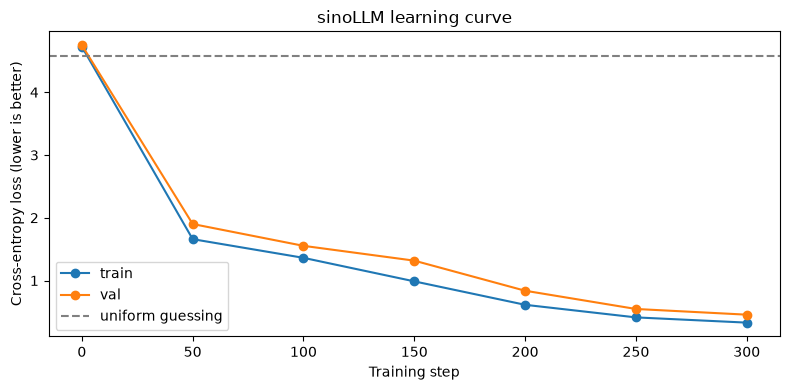

BEFORE:
the ]yssb^)^7+1,00At*|&M&L0V."A`<M2O!kx@r~  C/fOklOPg6
  6
BB;cFVBx}xu"|B;FV).wB}E.wOGBi;F} PXkia|O6/),)];i;7.66OGVn{= &}wXu]L&7@XKP).-V?..O3i.. 7u|
.6x.)Omk2.6/}Ek

AFTER:
the baks ar the rain.
the bird waits beside the ra tin.
the child s armer hers a quiet sound.
the armer waits besunde the door.
the che cartist waits beside the ra 

Held-out loss change: 4.294


In [11]:
plt.figure(figsize=(8, 4))
for split in ("train", "val"):
    plt.plot([row["step"] for row in history], [row[split] for row in history],
             marker="o", label=split)
plt.axhline(math.log(vocab_size), color="gray", linestyle="--", label="uniform guessing")
plt.xlabel("Training step"); plt.ylabel("Cross-entropy loss (lower is better)")
plt.title("sinoLLM learning curve"); plt.legend(); plt.tight_layout(); plt.show()

torch.manual_seed(7)
trained_text = generate_text()
print("BEFORE:\n" + untrained_text)
print("\nAFTER:\n" + trained_text)
print("\nHeld-out loss change:", round(history[0]["val"] - history[-1]["val"], 3))

## 10. Inspect one next-character decision
Generation does not choose a whole sentence at once. It predicts a distribution for the next character, samples one, appends it, then repeats. **Temperature** changes how concentrated the distribution is; **top-k** restricts sampling to the highest-scoring k characters. Neither adds knowledge.

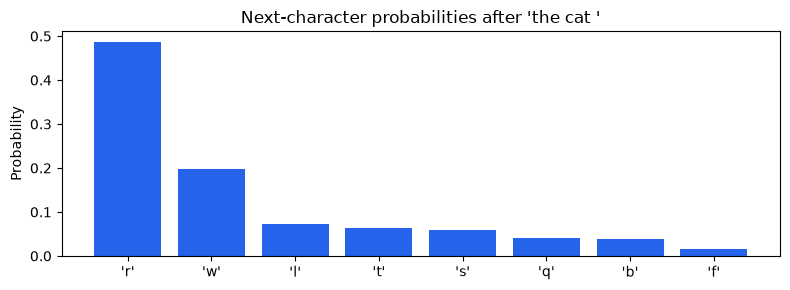

the cat rests under a tree.
the cartist a smal flky.
the bird liks the riks armer s the river.
the farmer waits beside the ra tin.
the baker looks at the blue sky.
the 


In [19]:
prompt = "the cat "
model.eval()
with torch.no_grad():
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)
    logits, _ = model(ids)
    probs = F.softmax(logits[0, -1], dim=-1).cpu()
values, indices = probs.topk(8)
plt.figure(figsize=(8, 3))
plt.bar([repr(itos[int(i)]) for i in indices], values.tolist(), color="#2563eb")
plt.title(f"Next-character probabilities after {prompt!r}")
plt.ylabel("Probability"); plt.tight_layout(); plt.show()
print(generate_text(prompt, temperature=0.7))

## 11. Inspect learned attention, and check that the future stays hidden
These are the actual first block's first-head attention weights for one input. Each row sums to one. White future cells must stay zero. A bright cell indicates more weight on that position; this alone does not explain the model's reasoning.

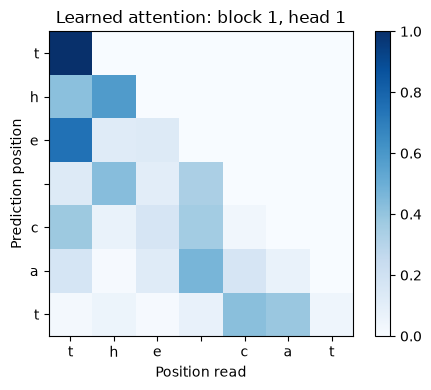

Passed: attention sums to 1, future weights are zero, and future edits cannot change the past.


In [13]:
model.eval()
with torch.no_grad():
    demo_ids = torch.tensor([encode("the cat")], device=DEVICE)
    positions = torch.arange(demo_ids.shape[1], device=DEVICE)
    vectors = model.token_embedding(demo_ids) + model.position_embedding(positions)
    block = model.blocks[0]
    _, attention = block.attention(block.norm1(vectors), return_weights=True)
weights = attention[0, 0].cpu()
assert torch.allclose(weights.sum(-1), torch.ones(weights.shape[0]), atol=1e-5)
assert torch.count_nonzero(torch.triu(weights, diagonal=1)) == 0
plt.figure(figsize=(5, 4))
plt.imshow(weights.numpy(), cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(7), list("the cat")); plt.yticks(range(7), list("the cat"))
plt.xlabel("Position read"); plt.ylabel("Prediction position")
plt.title("Learned attention: block 1, head 1"); plt.colorbar(); plt.tight_layout(); plt.show()

# Stronger check: changing future tokens must not change earlier predictions.
with torch.no_grad():
    original = demo_ids
    changed = original.clone()
    changed[:, 4:] = (changed[:, 4:] + 1) % vocab_size
    a, _ = model(original)
    b, _ = model(changed)
    torch.testing.assert_close(a[:, :4], b[:, :4], atol=1e-5, rtol=1e-5)
print("Passed: attention sums to 1, future weights are zero, and future edits cannot change the past.")

## 12. Save the model and tokenizer, then reload and compare
Weights alone are not enough: a model also needs its architecture settings and token-ID mapping. This checkpoint stores all three. We check that reloading reproduces the same logits. It is an **inference checkpoint**; it does not contain optimizer/RNG state for an exact training resume.

Only load checkpoints you trust. The example loads the file it just created using `weights_only=True`.

In [14]:
artifact_dir = Path(os.environ.get("SINO_ARTIFACT_DIR", "sinoLLM_artifacts"))
artifact_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = artifact_dir / "sinoLLM.pt"
# CPU weights make the checkpoint portable across CPU/CUDA/MPS machines.
torch.save({"config": config, "chars": chars,
            "model_state": {name: value.detach().cpu() for name, value in model.state_dict().items()},
            "training_steps": TRAIN_STEPS}, checkpoint_path)
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
loaded_model = SinoLLM(**checkpoint["config"]).to(DEVICE)
loaded_model.load_state_dict(checkpoint["model_state"])
loaded_model.eval(); model.eval()
loaded_stoi = {ch: i for i, ch in enumerate(checkpoint["chars"])}
loaded_itos = {i: ch for i, ch in enumerate(checkpoint["chars"])}
with torch.no_grad():
    probe = torch.tensor([[loaded_stoi[ch] for ch in "the cat"]], device=DEVICE)
    torch.testing.assert_close(model(probe)[0], loaded_model(probe)[0])
    generated = loaded_model.generate(probe, max_new_tokens=60)
print("Reloaded sample:", "".join(loaded_itos[i] for i in generated[0].tolist()))
print("Passed: original and reloaded model give the same logits.")
print("Checkpoint:", checkpoint_path)

Reloaded sample: the cat rests under a tre.
the cat watches rtis ait sthe blound.
th
Passed: original and reloaded model give the same logits.
Checkpoint: sinoLLM_artifacts/sinoLLM.pt


## 13. Experiments — change one thing at a time

1. **Train longer:** change `TRAIN_STEPS` from 300 to 600, then restart the kernel and Run All. Compare held-out loss and actual output, not just training loss.
2. **Try your existing text:** set `DATA_PATH = Path("input.txt")`. Restart and Run All. A larger, more varied corpus usually needs a larger training budget; this tiny run may produce poor text.
3. **Change context:** try 24 versus 48 characters. What information can the shorter model no longer see?
4. **Change sampling:** keep trained weights fixed and compare temperatures 0.5 and 1.2. Does more randomness make it better, or just more varied?
5. **Make it larger:** try `embedding_dim=96` with `num_heads=3`. Note parameter count and runtime. More parameters do not guarantee better results.

### What this teaches — and what comes next
You implemented tokenization, learned embeddings, positional information, multi-head causal attention, feed-forward layers, next-token loss, gradient updates, sampling, and checkpointing. Unlike your regression example, the output is a probability distribution over text tokens rather than a single number.

An effective assistant also needs much more diverse data, careful evaluation, and instruction tuning; this notebook demonstrates pretraining only. It has no chat roles, retrieval, tools, or factual reliability guarantee. It can reproduce text from its training data.

### Sources for further reading
- [PyTorch cross-entropy](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html)
- [PyTorch AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html)
- [PyTorch attention reference](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html) — our code spells the operations out for learning instead of calling the fused helper.
- [Attention Is All You Need](https://arxiv.org/abs/1706.03762) — original transformer paper; our model uses a small decoder-only variant.

## 14. Talk to sinoLLM now

**Run the cell below.** VS Code/Jupyter will ask for your message in an input box. Enter text and press Enter. Enter `quit` to finish; you can also interrupt the cell to stop.

Run sections 0–12 first (or **Run All**) so the trained model and tokenizer are available. Each prompt is independent: this tiny model has no conversation memory. It **continues your text**, rather than following instructions or answering questions. Try `the cat `, `my friend `, or `the bird ` first; even these can produce mistakes. Your messages do not train the model or change its weights. ASCII characters only.

The displayed response is only the newly generated continuation; it is produced by your local trained model, with no remote API.

In [ ]:
def sino_reply(message, max_new_tokens=120, temperature=0.7):
    if not message.strip():
        raise ValueError("Type a message first.")
    unknown = sorted(set(message) - set(loaded_stoi))
    if unknown:
        raise ValueError(f"Use ASCII text; unsupported characters: {unknown[:5]!r}")
    ids = torch.tensor([[loaded_stoi[ch] for ch in message]],
                       dtype=torch.long, device=next(loaded_model.parameters()).device)
    generated = loaded_model.generate(ids, max_new_tokens=max_new_tokens,
                                      temperature=temperature, top_k=12)
    continuation = generated[0, ids.shape[1]:].tolist()
    return "".join(loaded_itos[token] for token in continuation)


def talk_to_sino():
    if not all(name in globals() for name in ("loaded_model", "loaded_stoi", "loaded_itos")):
        print("Run sections 0–12 first, then run this cell again.")
        return
    print("sinoLLM is ready. It continues text; it is not trained to answer questions.")
    print("Try: the cat  |  my friend  |  the bird  — type quit to stop.")
    try:
        while True:
            message = input("You: ")
            if message.strip().lower() in {"quit", "exit", "/quit"}:
                print("Chat ended. Run this cell again whenever you want.")
                break
            try:
                reply = sino_reply(message)
            except ValueError as error:
                print(error)
                continue
            print("sinoLLM (continuation): " + reply + "\n")
    except (KeyboardInterrupt, EOFError):
        print("Chat stopped. Run this cell again to restart.")


talk_to_sino()